# Low-level EEG reconstruction comparison

This report compares the completed MSE-only, unaligned SynCLR, and aligned SynCLR low-level runs. Each model maps EEG directly to the latent consumed by the frozen 128px SDXL-Turbo VAE decoder. Metrics are loaded from the saved external evaluations; example reconstructions are regenerated from the selected checkpoints.

In [1]:
from pathlib import Path
import os
import gc
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

repo = Path.cwd().resolve() if (Path.cwd() / 'src').exists() else Path('..').resolve()
os.chdir(repo)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
runs = {
    'MSE': {
        'config_name': 'train_low_level',
        'run': repo / 'experiments/low_level/20260905_025455/train_low_level-20260905_025524/version_0',
    },
    'Unaligned SynCLR': {
        'config_name': 'train_low_level_dreamsim',
        'run': repo / 'experiments/low_level/unaligned_cached_20260905/train_low_level-20260905_180009/version_0',
    },
    'Aligned SynCLR': {
        'config_name': 'train_low_level_aligned_dreamsim',
        'run': repo / 'experiments/low_level/aligned_cached_20260906/train_low_level-20260906_140857/version_0',
    },
}
for name, info in runs.items():
    info['metrics'] = pd.read_csv(info['run'] / 'test/test_metrics.csv')
    info['evaluation'] = yaml.safe_load((info['run'] / 'test/evaluation_config.yaml').read_text())
    info['checkpoint'] = Path(info['evaluation']['checkpoint_path'])
    if not info['checkpoint'].is_absolute():
        info['checkpoint'] = repo / info['checkpoint']
    assert info['checkpoint'].exists(), info['checkpoint']
    assert info['evaluation']['dataset']['test_batch_size'] == 1
    assert info['evaluation']['model']['vae_encoder'] == 'ip_sdxl_turbo_128'
print('device:', device)
[(name, info['config_name'], info['checkpoint'].name) for name, info in runs.items()]

device: cuda


[('MSE', 'train_low_level', 'epoch_0159-val_loss_0.6073.ckpt'),
 ('Unaligned SynCLR',
  'train_low_level_dreamsim',
  'epoch_0089-val_loss_0.8114.ckpt'),
 ('Aligned SynCLR',
  'train_low_level_aligned_dreamsim',
  'epoch_0069-val_loss_0.9002.ckpt')]

## Evaluation metrics

The scalar loss values are not treated as directly comparable across all rows: MSE contains only the latent L2 term, while the SynCLR runs contain L2 plus their respective perceptual term. The image metrics are compared directly.

,MSE,Unaligned SynCLR,Aligned SynCLR
pixcorr,0.24312,0.19760,0.18591
ssim,0.36691,0.41711,0.40851
alex2,0.70161,0.73156,0.79050
alex5,0.69646,0.71171,0.73146
inceptionv3,0.54789,0.54251,0.56136
clip,0.51616,0.55246,0.53809
efficientnet,0.97387,0.98683,0.98864
swav,0.75494,0.72113,0.72373
dreamsim_aligned,0.78772,0.72158,0.68863
dreamsim_unaligned,0.55785,0.54377,0.55835


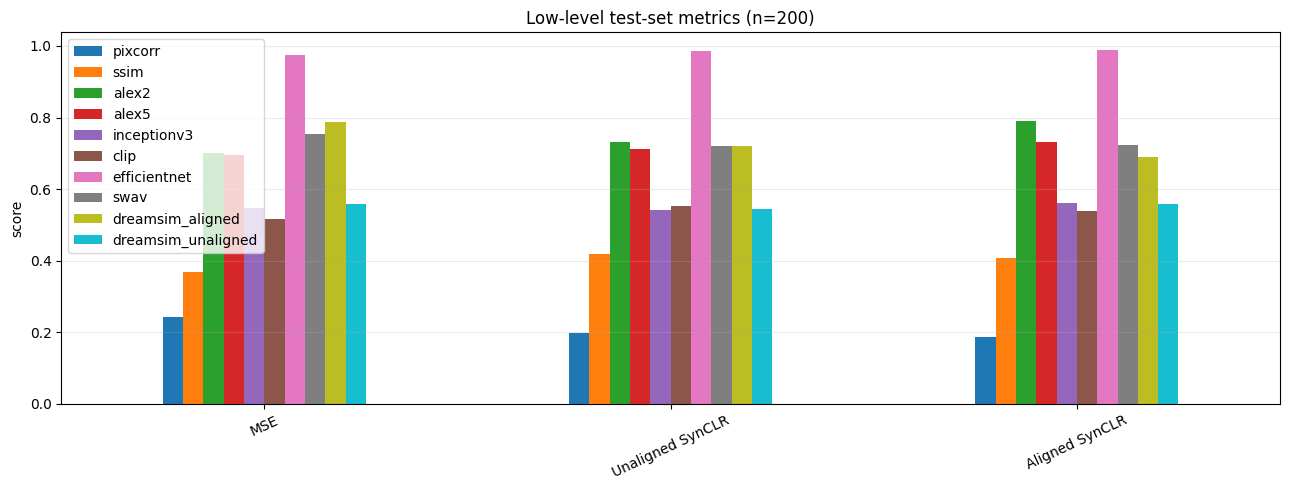

In [2]:
metric_order = [
    'test/pixcorr', 'test/ssim', 'test/alex2', 'test/alex5',
    'test/inceptionv3', 'test/clip', 'test/efficientnet', 'test/swav',
    'test/dreamsim_aligned', 'test/dreamsim_unaligned',
]
metric_table = pd.DataFrame({
    name: info['metrics'].set_index('metric')['value']
    for name, info in runs.items()
}).loc[metric_order]
metric_table.index = [m.removeprefix('test/') for m in metric_table.index]
display(metric_table.style.format('{:.5f}'))

ax = metric_table.T.plot.bar(figsize=(13, 5), rot=25)
ax.set_ylabel('score')
ax.set_title('Low-level test-set metrics (n=200)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## Matched example reconstructions

The same five test-set positions are used for every model. Predictions are generated one example at a time in evaluation mode and saved below each run's `test/reconstructions/` directory.

In [3]:
import sys
sys.path.insert(0, str(repo))
from brain_image.model.low_level import LowLevelModule
from scripts.training.train_low_level import TrainLowLevelConfig
from hydra import compose, initialize_config_dir
from brain_image.configs import GlobalConfig
from brain_image.data.io import batch_load_images

example_indices = [0, 50, 100, 150, 199]
generated = {}
ground_truth = {}

def load_run_config(config_name):
    with initialize_config_dir(config_dir=str(GlobalConfig.CONFIGS_DIR), version_base=None):
        cfg = compose(
            config_name=config_name,
            overrides=[
                'trainer.compile_model=false',
                'trainer.wandb.enabled=false',
                'dataset.batch_size=1',
                'dataset.val_batch_size=1',
                'dataset.test_batch_size=1',
                'model.eval_batch_size=1',
            ],
        )
        return TrainLowLevelConfig.from_hydra_config(cfg)

for name, info in runs.items():
    cfg = load_run_config(info['config_name'])
    model = LowLevelModule(cfg.model, cfg.dataset, compile=False).to(device)
    checkpoint = torch.load(info['checkpoint'], map_location='cpu', weights_only=False)
    model.load_state_dict(checkpoint['state_dict'], strict=True)
    model.eval()
    dataset = model.data_module.get_dataset('test')
    output_dir = info['run'] / 'test/reconstructions'
    output_dir.mkdir(parents=True, exist_ok=True)
    generated[name] = {}
    for index in example_indices:
        sample = dataset[index]
        img_path = Path(sample['img_path'])
        if index not in ground_truth:
            ground_truth[index] = batch_load_images([str(img_path)])[0].cpu()
        with torch.no_grad():
            eeg = sample['eeg_data'].unsqueeze(0).to(device)
            eeg_latent = model.eeg_encoder(eeg)
            low_level_latent = model.low_level_encoder(eeg_latent)
            prediction = model.vae_encoder.decode(low_level_latent)[0].cpu()
        generated[name][index] = prediction
        image = (prediction.clamp(0, 1).permute(1, 2, 0).numpy() * 255).astype('uint8')
        Image.fromarray(image).save(output_dir / f'example_{index:03d}.png')
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

assert all(len(values) == len(example_indices) for values in generated.values())
print('saved reconstruction directories:')
for name, info in runs.items():
    print(name, info['run'] / 'test/reconstructions')

/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadat

/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Seed set to 42


INFO:lightning_fabric.utilities.seed:Seed set to 42


/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


...

INFO:lightning_fabric.utilities.seed:Seed set to 42


Using cached models


Using cached models


/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:305: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


saved reconstruction directories:
MSE /home/gasparyanartur/dev/brain-image-implementation/experiments/low_level/20260905_025455/train_low_level-20260905_025524/version_0/test/reconstructions
Unaligned SynCLR /home/gasparyanartur/dev/brain-image-implementation/experiments/low_level/unaligned_cached_20260905/train_low_level-20260905_180009/version_0/test/reconstructions
Aligned SynCLR /home/gasparyanartur/dev/brain-image-implementation/experiments/low_level/aligned_cached_20260906/train_low_level-20260906_140857/version_0/test/reconstructions


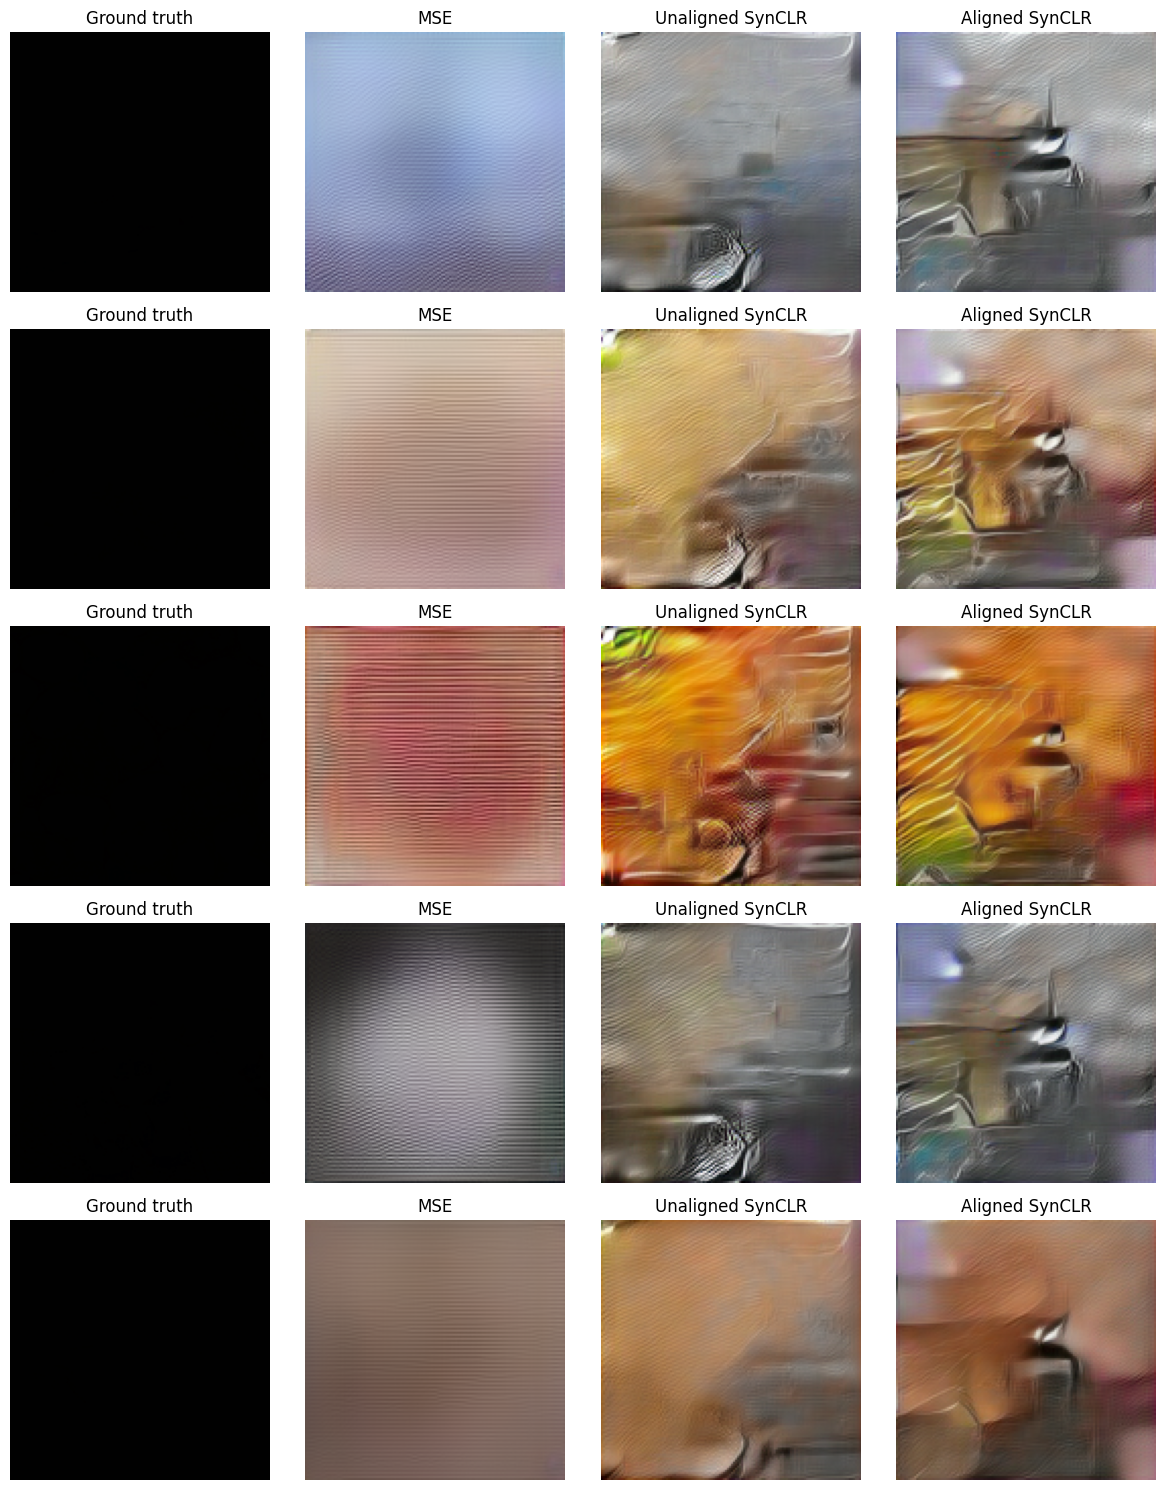

In [4]:
fig, axes = plt.subplots(len(example_indices), 4, figsize=(12, 3 * len(example_indices)))
if len(example_indices) == 1:
    axes = axes[None, :]
for row, index in enumerate(example_indices):
    images = [ground_truth[index]] + [generated[name][index] for name in runs]
    titles = ['Ground truth'] + list(runs)
    for col, (image, title) in enumerate(zip(images, titles)):
        axes[row, col].imshow(image.permute(1, 2, 0).clamp(0, 1))
        axes[row, col].set_title(title)
        axes[row, col].axis('off')
    axes[row, 0].set_ylabel(f'test index {index}', rotation=90, size=10)
plt.tight_layout()
plt.show()

## Summary

The MSE-only, unaligned, and aligned runs use the same low-level architecture and VAE target. The perceptual runs differ only in the cached SynCLR target used by the additional loss. The table and image grids above should be interpreted together: feature metrics can improve even when pixel correlation or structural similarity moves in the opposite direction.